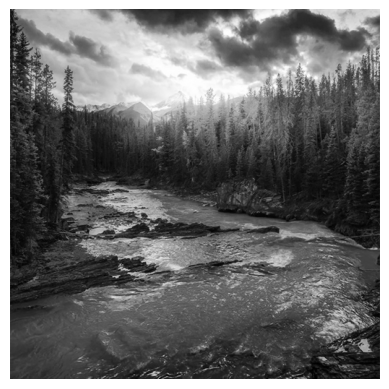

In [8]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

image = cv.imread('c2.jpg')
image_gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

plt.axis("off")
plt.imshow(image_gray, cmap="gray")

In [9]:
def haar_rows(img):
    a = img[:, 0::2]
    b = img[:, 1::2]
    approx = (a + b) / 2
    detail = (a - b) / 2
    return np.concatenate([approx, detail], axis=1)

def haar_2d(img):
    rows = haar_rows(img)
    return haar_rows(rows.T).T

shape для разложения: (512, 512)


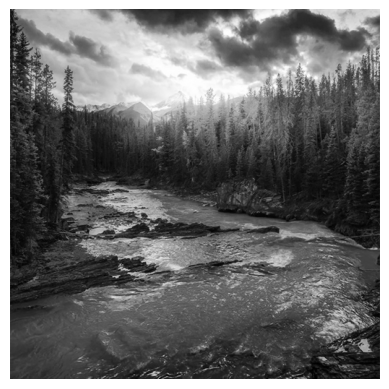

In [10]:

h, w = image_gray.shape
h8 = (h // 8) * 8
w8 = (w // 8) * 8

img = image_gray[:h8, :w8].astype(np.float64)
print("shape для разложения:", img.shape)

plt.axis("off")
plt.imshow(img, cmap="gray")

In [11]:
lvl1 = haar_2d(img)
lvl2 = lvl1.copy(); lvl2[:h8//2, :w8//2] = haar_2d(lvl1[:h8//2, :w8//2])
lvl3 = lvl2.copy(); lvl3[:h8//4, :w8//4] = haar_2d(lvl2[:h8//4, :w8//4])

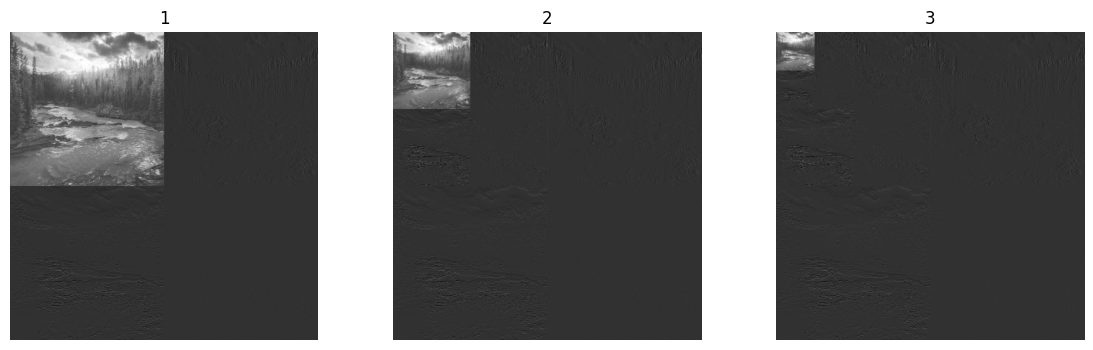

In [12]:
def norm_uint8(a):
    a = a.astype(np.float64)
    mn, mx = a.min(), a.max()
    if mx - mn < 1e-8:
        return np.zeros_like(a, dtype=np.uint8)
    return np.uint8((a - mn) / (mx - mn) * 255)

plt.figure(figsize=(14, 4))
plt.subplot(131), plt.imshow(norm_uint8(lvl1), cmap="gray"), plt.title("1"), plt.axis("off")
plt.subplot(132), plt.imshow(norm_uint8(lvl2), cmap="gray"), plt.title("2"), plt.axis("off")
plt.subplot(133), plt.imshow(norm_uint8(lvl3), cmap="gray"), plt.title("3"), plt.axis("off")
plt.show()

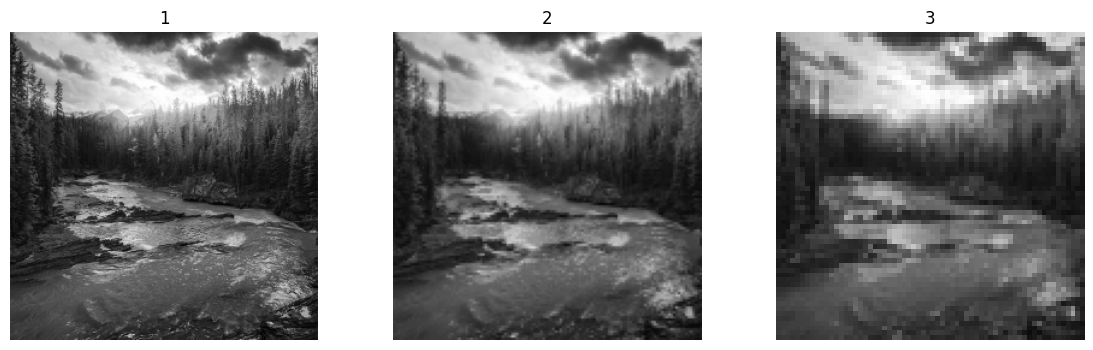

In [13]:
plt.figure(figsize=(14, 4))
plt.subplot(131), plt.imshow(lvl1[:h8//2, :w8//2], cmap="gray", vmin=0, vmax=255), plt.title("1"), plt.axis("off")
plt.subplot(132), plt.imshow(lvl2[:h8//4, :w8//4], cmap="gray", vmin=0, vmax=255), plt.title("2"), plt.axis("off")
plt.subplot(133), plt.imshow(lvl3[:h8//8, :w8//8], cmap="gray", vmin=0, vmax=255), plt.title("3"), plt.axis("off")
plt.show()